In [5]:
import pandas
train = pandas.read_csv('train.csv')
test = pandas.read_csv('test.csv')


In [6]:
print(train.shape)
print(train.info())
print(train.isnull().sum())
print(train.duplicated().sum())
print(train.head())

(511, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 511 entries, 0 to 510
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   PhraseId    511 non-null    int64 
 1   SentenceId  511 non-null    int64 
 2   Phrase      511 non-null    object
 3   Sentiment   511 non-null    int64 
dtypes: int64(3), object(1)
memory usage: 16.1+ KB
None
PhraseId      0
SentenceId    0
Phrase        0
Sentiment     0
dtype: int64
0
   PhraseId  SentenceId                                             Phrase  \
0    144934        7871  An unremittingly ugly movie to look at , liste...   
1    137519        7440           Makes 98 minutes feel like three hours .   
2     70201        3575  -LRB- N -RRB- o matter how much good will the ...   
3     19954         885  An erotic thriller that 's neither too erotic ...   
4    101128        5315  Bray is completely at sea ; with nothing but a...   

   Sentiment  
0          0  
1          0 

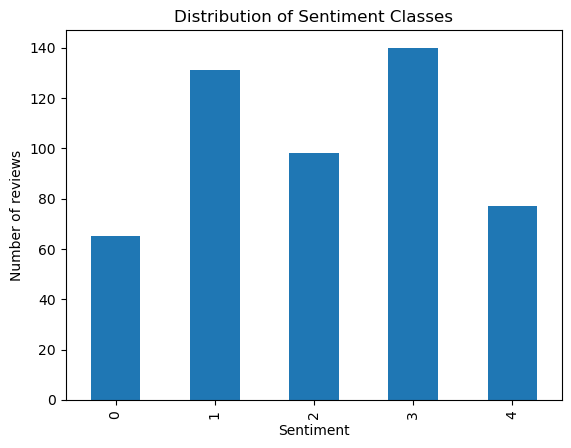

In [7]:
import matplotlib.pyplot as plt

train["Sentiment"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.title("Distribution of Sentiment Classes")
plt.show()

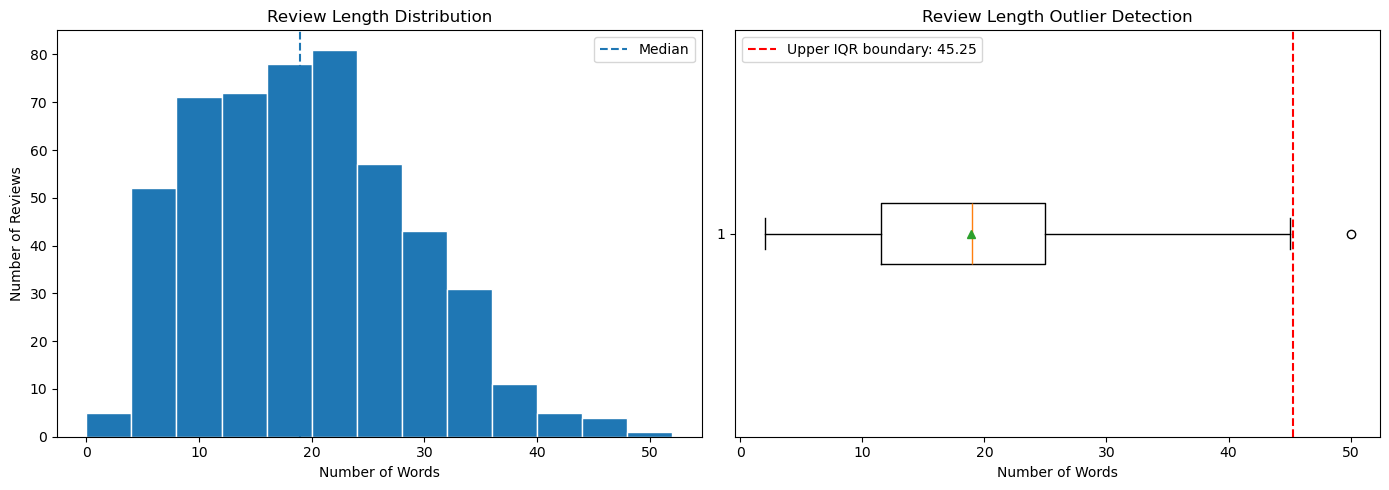

Mean: 18.92 words
Median: 19.00 words
Minimum: 2 words
Maximum: 50 words
IQR upper boundary: 45.25 words
Number of outliers: 1


,Phrase,Sentiment,WordCount
393,When it 's not wallowing in hormonal melodrama...,3,50


In [8]:


import numpy as np


# Combine original training and validation data
df = train.copy()

# Calculate number of words per review
df["WordCount"] = df["Phrase"].fillna("").str.split().str.len()

# IQR outlier detection
Q1 = df["WordCount"].quantile(0.25)
Q3 = df["WordCount"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["WordCount"] < lower) |
    (df["WordCount"] > upper)
]

# Create plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Histogram
axes[0].hist(
    df["WordCount"],
    bins=np.arange(0, 56, 4),
    edgecolor="white"
)
axes[0].axvline(
    df["WordCount"].median(),
    linestyle="--",
    label="Median"
)
axes[0].set_title("Review Length Distribution")
axes[0].set_xlabel("Number of Words")
axes[0].set_ylabel("Number of Reviews")
axes[0].legend()

# 2. Box plot
axes[1].boxplot(
    df["WordCount"],
    vert=False,
    showmeans=True
)
axes[1].axvline(
    upper,
    color="red",
    linestyle="--",
    label=f"Upper IQR boundary: {upper:.2f}"
)
axes[1].set_title("Review Length Outlier Detection")
axes[1].set_xlabel("Number of Words")
axes[1].legend()

plt.tight_layout()
plt.show()

# Print results
print(f"Mean: {df['WordCount'].mean():.2f} words")
print(f"Median: {df['WordCount'].median():.2f} words")
print(f"Minimum: {df['WordCount'].min()} words")
print(f"Maximum: {df['WordCount'].max()} words")
print(f"IQR upper boundary: {upper:.2f} words")
print(f"Number of outliers: {len(outliers)}")

display(outliers[["Phrase", "Sentiment", "WordCount"]])
